# 09 · Reproduce the YOLO11n Training (opt-in)

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Let a user with the prepared dataset and an NVIDIA GPU re-run the historical 200-epoch E.1c experiment with exactly the same configuration, through the same guarded trainer. **Training is disabled by default. Run All only performs checks and a dry run.**

**Research questions**

1. What exactly was trained, and with which settings and initialisation?
2. Is this machine and dataset ready to reproduce it?
3. How is a new run launched safely, and how should its results be compared?

**Inputs (published, pixel-free artifacts)**

- `artifacts/training/e1c_train_config.json`
- `artifacts/training/e1c_args.yaml`
- `data/release/yolo-rock-v1.1-configA.files.sha256`
- `backend/training/train.py (guarded trainer)`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. The historical experiment (E.1c)
| Item | Value |
|---|---|
| Model | YOLO11n, initialised from the official COCO-pretrained `yolo11n.pt` (SHA-256 `0ebbc80d…44ee1`) |
| Data | `yolo-rock-v1.1` **Config A**: 1,903 training scenes; validation 923 |
| Schedule | 200 epochs, batch 16, imgsz 736, SGD (lr0 0.01, momentum 0.937, wd 5e-4), cosine LR, 3 warm-up epochs, mosaic closed for the last 10 epochs |
| Precision / seed | AMP fp16, `deterministic=true`, seed 42 |
| Hardware / time | RTX 5060 Laptop GPU (8 GB): **68.7 min**, peak VRAM 5.5 GB, peak system RAM 25.9 GB |
| Outcome | Converged by about epoch 100-120; selected checkpoint at epoch 111 |

In [2]:
from artemis_x.ml import training_repro as T
h = T.historical_config()
pd.Series({"arm": h["arm"]["id"], "seed": h["seed"], "status": h["status"], "epochs completed": h["epochs_completed"],
           **{f"override: {k}": str(v) for k, v in h["overrides"].items()}}).to_frame("E.1c")

,E.1c
arm,A_steps
seed,42
status,COMPLETED
epochs completed,200
override: epochs,200
override: save_period,10
override: imgsz,736
override: batch,16
override: workers,4
override: device,0


In [3]:
keys = ["model", "pretrained", "epochs", "batch", "imgsz", "optimizer", "lr0", "lrf", "momentum", "weight_decay", "cos_lr",
        "warmup_epochs", "close_mosaic", "mosaic", "fliplr", "hsv_v", "amp", "seed", "deterministic", "single_cls", "patience", "save_period"]
pd.DataFrame({"E.1c effective value": [str(h["effective_args"].get(k)) for k in keys]}, index=keys)   # str: no rounding

,E.1c effective value
model,yolo11n.pt
pretrained,True
epochs,200
batch,16
imgsz,736
optimizer,SGD
lr0,0.01
lrf,0.01
momentum,0.937
weight_decay,0.0005


## 2. Requirements
- **Dataset:** the prepared release `yolo-rock-v1.1-configA` (about 1.8 GB). It is **not published yet**, pending licence
  approval; see `docs/DATASET_DISTRIBUTION_PLAN.md`. Once a release exists:
  `uv run --project backend python scripts/download_dataset.py --source <approved source>`.
  It verifies all 7,490 files against the committed SHA-256 manifest.
- **Pretrained weights:** `backend/yolo11n.pt`, the official Ultralytics asset. Its SHA-256 is checked below.
- **Hardware:** an NVIDIA GPU with at least 8 GB VRAM (5.5 GB peak observed), at least 32 GB system RAM recommended (validation
  peaked at 25.9 GB used), and about 1.5 GB of free disk per run (checkpoints every 10 epochs). CPU-only training is technically
  possible but was not measured and would be impractically slow.
- **Software:** the locked environment (`backend/uv.lock`: torch 2.14.1 + CUDA 13.0, Ultralytics 8.4.174).

## 3. Preflight (no training)
Dataset verification hashes all labels and manifests and every 50th image (`full_hash=True` hashes everything).

In [4]:
pf = T.preflight(full_hash=False)
ds = pf["dataset"]
display(pd.Series({"dataset files in manifest": ds.get("files_in_manifest"), "hashed": ds.get("hashed"), "missing": ds.get("n_missing"),
                   "mismatched": ds.get("n_mismatched"), "split counts as expected": ds.get("counts_match_expected"), "dataset ok": ds.get("ok")}).to_frame("prepared dataset"))
display(pd.Series(pf["pretrained"]).to_frame("pretrained initialisation"))
display(pd.Series(pf["environment"]).to_frame("environment"))
print("READY TO REPRODUCE:", pf["ready"])

,prepared dataset
dataset files in manifest,7490
hashed,3822
missing,0
mismatched,0
split counts as expected,True
dataset ok,True


,pretrained initialisation
path,backend/yolo11n.pt
present,True
sha256_ok,True
hint,None


,environment
python,3.12.13
torch,2.14.1+cu130
cuda,True
gpu,NVIDIA GeForce RTX 5060 Laptop GPU
vram_gb,7.9
enough_vram,True
ultralytics,8.4.174
ultralytics_matches_e1c,True


READY TO REPRODUCE: True


## 4. Plan the run and resolve the exact arguments (dry run)
Outputs go to `experiments/reproductions/<RUN_NAME>/`. The planner refuses to write into `experiments/task-e`,
`experiments/task-f`, `models/` or `artifacts/`, and refuses to reuse a run folder that already holds checkpoints. A reproduction
appends to `experiments/reproductions/reproductions_registry.jsonl`, never to the historical registry. The dry run asks the real
trainer to resolve its arguments without touching the GPU.

In [5]:
RUN_NAME = "repro-config-a-200-s42"
plan = None
if pf["dataset"].get("ok"):
    plan = T.plan_run(name=RUN_NAME)
    resolved = T.dry_run(plan)
    a = resolved["ultralytics_args"]
    display(pd.Series({"run folder": resolved["run_dir"], **{k: a[k] for k in ("data", "epochs", "batch", "imgsz", "workers", "seed", "optimizer",
                       "lr0", "cos_lr", "amp", "deterministic", "single_cls", "save_period", "close_mosaic")}}).to_frame("resolved by the trainer"))
else:
    print("Prepared dataset not available - see section 2. Nothing planned.")

,resolved by the trainer
run folder,experiments/reproductions/repro-config-a-200-s42
data,experiments/reproductions/repro-config-a-200-s42.data_A.yaml
epochs,200
batch,16
imgsz,736
workers,4
seed,42
optimizer,SGD
lr0,0.01
cos_lr,True


## 5. Launch (disabled by default)
Training starts only if **both** values below are changed by hand: `RUN_TRAINING = True`, and `AUTHORISATION` set to the exact
phrase `I authorise one 200-epoch YOLO11n training run`. The trainer then additionally requires its own authorisation flag and
environment variable, which are set for that single subprocess only. It refuses to resume, change the batch size after an OOM, replay
NaN epochs, or exceed 200 epochs. **Under Run All this cell does nothing.**

In [6]:
RUN_TRAINING = False      # must be changed by hand
AUTHORISATION = ""        # must equal T.AUTH_PHRASE exactly
exit_code = T.launch(plan, run=RUN_TRAINING, authorisation=AUTHORISATION) if plan else None
exit_code

Training NOT started. Set RUN_TRAINING = True and AUTHORISATION = the exact phrase to launch one run.


## 6. Comparing a reproduction with the original
Compare on the **validation split only**: the held-out test split has already been used once and must not be used again for
model choice.

1. Plot the reproduced `results.csv` against `artifacts/training/results.csv` (cell below).
2. Score the reproduced checkpoints with the ignore-aware evaluator
   (`backend/training/evaluate.py --weights <run>/weights/best.pt --split val`).
3. Treat differences of about ±0.01 AP50 as noise: single-seed checkpoint variability was of that order in E.1c.

**Numerical reproducibility limits:**
- GPU kernels (cuDNN, AMP) are not bitwise deterministic, even with `deterministic=true` and seed 42.
- Results also depend on the GPU model, driver, CUDA, PyTorch and Ultralytics versions, and on the number of data-loader workers.
- Expect similar curves and metrics, not identical weights. The frozen model (`models/artemis_rock_yolo11n.pt`) is never
  replaced by a reproduction.

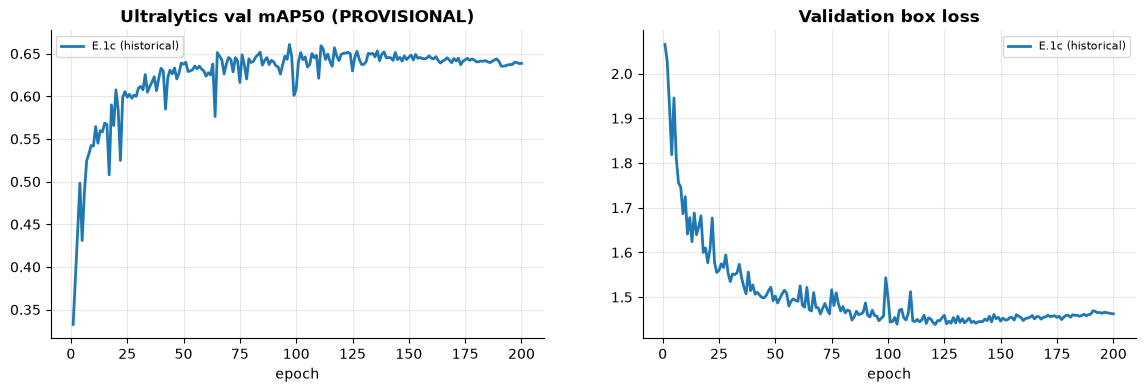

0 reproduction(s) found


In [7]:
import matplotlib.pyplot as plt
hist = A.training_history()
runs = sorted((paths.EXPERIMENTS / "reproductions").glob("*/results.csv")) if (paths.EXPERIMENTS / "reproductions").exists() else []
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(hist["epoch"], hist["metrics/mAP50(B)"], label="E.1c (historical)", lw=2)
ax[1].plot(hist["epoch"], hist["val/box_loss"], label="E.1c (historical)", lw=2)
for r in runs:
    d = pd.read_csv(r); d.columns = [x.strip() for x in d.columns]
    ax[0].plot(d["epoch"], d["metrics/mAP50(B)"], label=r.parent.name); ax[1].plot(d["epoch"], d["val/box_loss"], label=r.parent.name)
ax[0].set_title("Ultralytics val mAP50 (PROVISIONAL)"); ax[1].set_title("Validation box loss")
for a_ in ax: a_.set_xlabel("epoch"); a_.legend(fontsize=8)
plt.show()
print(f"{len(runs)} reproduction(s) found")

## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [8]:
A.provenance(['training/e1c_train_config.json', 'training/e1c_args.yaml', 'training/results.csv'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/training/e1c_train_config.json,SANITISED,experiments/task-e/full-training-config-a-200-s42/train_config.json,f43a3c68e44e6cc7...
1,artifacts/training/e1c_args.yaml,SANITISED,experiments/task-e/full-training-config-a-200-s42/args.yaml,d41cffc35e52aa3e...
2,artifacts/training/results.csv,COPY,experiments/task-e/full-training-config-a-200-s42/results.csv,25c030b08c79d59a...


## Conclusion
- The historical configuration is fully specified and resolved by the same guarded trainer that produced E.1c.
- Reproducing it needs the prepared dataset release (pending licence approval), the official pretrained weights, an 8 GB NVIDIA GPU
  and about 70 minutes.
- Reproductions are isolated from the historical evidence, and the frozen model is never replaced.